In [2]:
import torch
import torch.nn as nn
import snntorch as snn

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

In [4]:

class SNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(8, 2)
        # Leaky : Leaky Integrate-and-Fire
        self.lif = snn.Leaky(beta=0.9)

    def forward(self, x):
        mem = torch.zeros(x.size(1), 2, device=x.device)
        spike_count = 0

        for t in range(x.size(0)):
            spk, mem = self.lif(self.fc(x[t]), mem)
            spike_count = spike_count + spk

        return spike_count


# Leaky
snn.Leaky : Leaky Integrate-and-Fire
Integrate는 charing단계. 이때 지속적으로 Leaky가 발생하는 거고. 만약 (Integrate > leaky) -> fire -> reset

```
\(U[t+1]=\beta U[t]+I_{in}[t+1]-S[t]U_{thr}\)
```
-> 모르겠네요

단, beta = 0.9 -> step마다 90%만 유지 (10%유출)
0~1 (1 = no leak)
참고 : threshold (default=1)

```
class SpikingNeuron extends Module { }
class LIF extends SpikingNeuron { }
class Leaky extends LIF { }
```
| torch.nn.Module : PyTorch 신경망 기본 클래스

# Forward
x ??
x {size, device} -> dict...? (x)
이런...


In [7]:
# replace


class SNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(8, 2)
        self.lif = snn.Leaky(beta=0.9)

    def forward(self, spike_sequence: torch.Tensor) -> torch.Tensor:
        """
        Args:
            spike_sequence:
                Shape: (time_steps, batch_size, features)
                - time_steps: 시간 단계 개수
                - batch_size: 데이터 개수
                - features: 8개의 입력 특성

        Returns:
            torch.Tensor:
                Shape: (batch_size, 2)
                각 클래스 뉴런의 누적 스파이크 수
        """

        # 입력 형상 검증
        if spike_sequence.ndim != 3 or spike_sequence.size(2) != 8:
            raise ValueError(
                "Expected shape (time_steps, batch_size, 8)"
            )

        batch_size = spike_sequence.size(1)

        mem = spike_sequence.new_zeros(batch_size, 2)
        spike_count = 0

        for t in range(spike_sequence.size(0)):
            current = self.fc(spike_sequence[t])
            spk, mem = self.lif(current, mem)
            spike_count = spike_count + spk

        return spike_count


x is torch.Tensor
size(0) = 0차원의 원소 개수
추후 torch.rand(12,64,8) 할 예정 -> 3차원의 텐서

# 텐서란?
| 텐서는 숫자들을 여러 차원으로 배열하고, 그 배열의 크기·자료형·연산 장치 등의 정보를 함께 관리하는 자료구조
`torch.rand(12, 64, 8)` ~~ `float[][][] x = new float[12][64][8];`

```python
x = torch.rand(12, 64, 8, device="mps")

print(x.shape)   # torch.Size([12, 64, 8])
print(x.ndim)    # 3
print(x.dtype)   # torch.float32
print(x.device)  # mps:0
```

# 다시 돌아와서
33번 line부터
Tensor.new_zeros(batch_size, 2) : r x c 의 0으로 채워진 텐서

current = self.fc(spike_sequence[t])
0차원에서 2차원 꺼냄 -> 64x8 (linear에 의해  8 -> 2로 압축됨)

3차원이 의미하는 걸 알아야함
dim0 : step (time)
dim1 : 데이터 개수 (64, batch size)
dim2 : 해당 데이터의 특성 (features)

->-> 64 x 2
 lif가 leaky intergrate and fire 수행



In [ ]:

model = SNN().to(device)
optimizer = torch.optim.Adam(model.parameters()) # Adam optimizer, 여기선 가중치와 편향을 적절히 조절

x = torch.rand(12, 64, 8, device=device)
y = torch.randint(0, 2, (64,), device=device) # [0, 2)의 값 중 하나 -> {0,1} & 64개 크기로 1차원 텐서 표현. python에서 1차원 튜플 표현을 위해 쉼표 사용 -> 정답 라벨링 (랜덤)

model.train() # 학습 모드로 전환
optimizer.zero_grad() # (옵티마이저 기울기 초기화, 사실 복수의 epoch에서 써야 의미 있음)
output = model(x) # forward 실행됨 (12 steps)
loss = nn.functional.cross_entropy(output, y) # 스파이크 누적과 정답 비교 -> loss
loss.backward() # 어떻게 해야 손실을 줄일 수 있을지 계산 (기울기 계산, model.weight.grad, model.bias.grad 로 따로따로임)
optimizer.step() # 기울기를 바탕으로 가중치와 편향 조절

model.eval() # 평가 모드 (예측)
with torch.no_grad(): # 이제 backward필요 없으니 기울기 계산 안 함
    prediction = model(x).argmax(dim=1) # 스파이크 누적 다시 예측 -> dim=2 에서 더 큰 값을 가진 index로 채워짐 (더 많은 스파이크를 발생한 뉴런 선택)

print("Device:", device)
print("Loss:", loss.item())
print("Predictions:", prediction[:10])

여기서 파라미터는 2개
1. weight
2. bias

Linear에 있음. (위 두 파라미터)

# 시각화


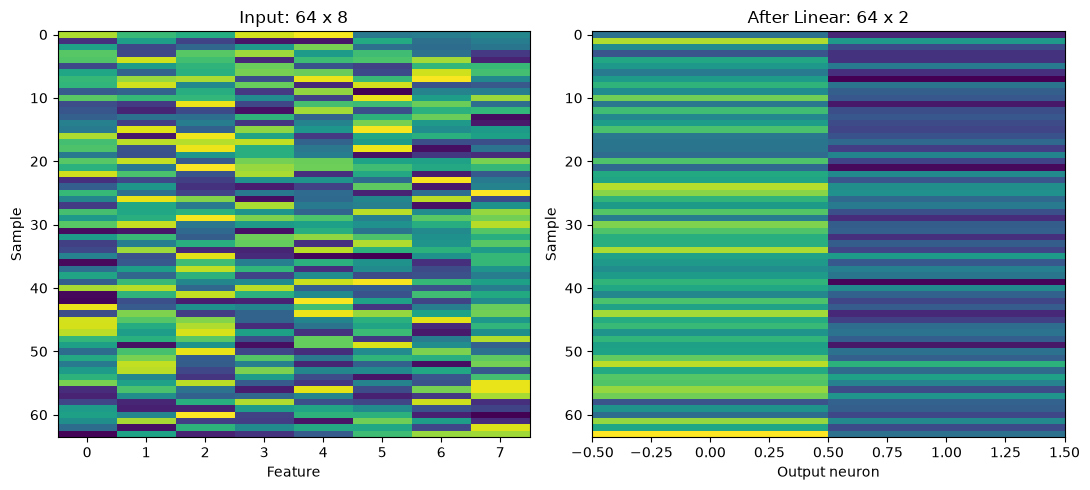

In [9]:

import torch
import torch.nn as nn
import snntorch as snn
import matplotlib.pyplot as plt

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

torch.manual_seed(0)

linear = nn.Linear(8, 2).to(device)
lif = snn.Leaky(beta=0.9).to(device)

# 12개 시간 단계, 64개 샘플, 특성 8개
x = torch.rand(12, 64, 8, device=device)

# 첫 번째 시간 단계 선택
time_step_input = x[0]  # (64, 8)

# Linear 계층을 통과한 결과
current = linear(time_step_input)  # (64, 2)

# GPU Tensor를 그래프용 CPU 배열로 변환
input_array = time_step_input.detach().cpu().numpy()
current_array = current.detach().cpu().numpy()

# 입력과 출력을 각각 히트맵으로 표시
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(input_array, aspect="auto")
axes[0].set_title("Input: 64 x 8")
axes[0].set_xlabel("Feature")
axes[0].set_ylabel("Sample")

axes[1].imshow(current_array, aspect="auto")
axes[1].set_title("After Linear: 64 x 2")
axes[1].set_xlabel("Output neuron")
axes[1].set_ylabel("Sample")

plt.tight_layout()
plt.show()



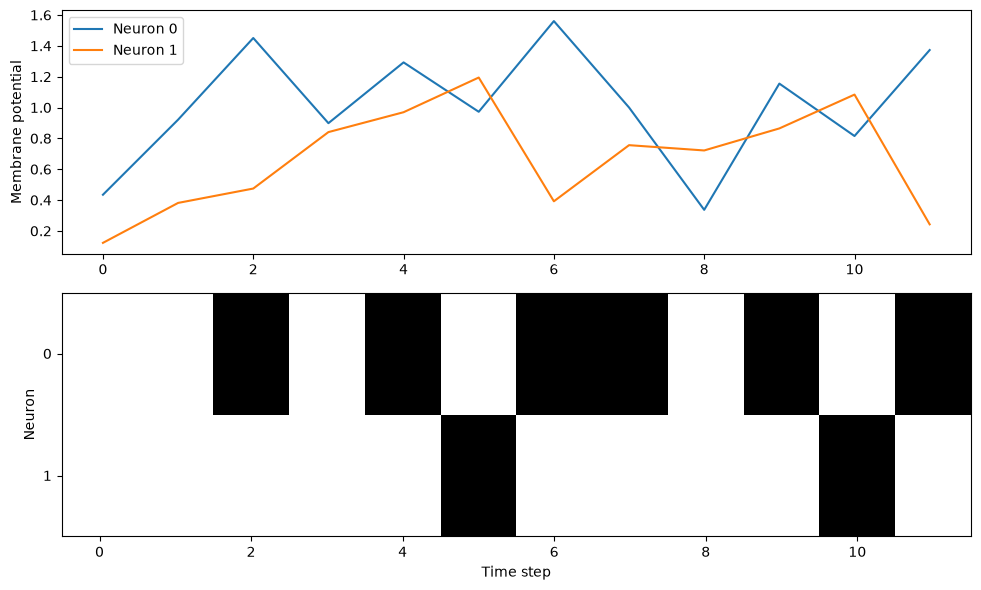

In [10]:

# 뉴런이 실제로 발화하는 모습을 보기 위한 실험용 편향
# 학습이 아니라 시각화 목적
with torch.no_grad():
    linear.bias.fill_(0.7)

# 64개 데이터 × 2개 뉴런의 초기 막전위
mem = x.new_zeros(64, 2)

mem_history = []
spike_history = []

# 시간 단계별 계산 기록
with torch.no_grad():
    for t in range(x.size(0)):
        current = linear(x[t])
        spikes, mem = lif(current, mem)

        # 64개 데이터 중 첫 번째 샘플만 기록
        mem_history.append(mem[0].cpu())
        spike_history.append(spikes[0].cpu())

mem_history = torch.stack(mem_history).numpy()
spike_history = torch.stack(spike_history).numpy()

# 시각화
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

# 시간에 따른 막전위
axes[0].plot(mem_history[:, 0], label="Neuron 0")
axes[0].plot(mem_history[:, 1], label="Neuron 1")
axes[0].set_ylabel("Membrane potential")
axes[0].legend()

# 각 시간 단계에서 발화한 뉴런 표시
axes[1].imshow(
    spike_history.T,
    aspect="auto",
    cmap="Greys",
    interpolation="nearest",
    vmin=0,
    vmax=1
)
axes[1].set_yticks([0, 1])
axes[1].set_ylabel("Neuron")
axes[1].set_xlabel("Time step")

plt.tight_layout()
plt.show()


# 결론
오늘은 pytorch, snntorch에 대해 익힘
SNN(Spiking neural network)은 뉴런 모방
그 중 Leaky Integrate-and-Fire 를 사용해봄. (Module->SNN->LIF->Leaky)
텐서는 다차원 리스트를 쉽게 다룰 수 있게 만든 자료구조

model.backward, train, eval